# Инфляция с членом Гаусса–Бонне: фон и спектры возмущений

Ноутбук-версия `Gauss_Bonne_cs_2.py` (автор NAAvd, 2024). Модель из arXiv:2403.06147:

$$V = \tfrac12 V_0 |\phi|^{\alpha}, \qquad f(\phi) = \frac{C}{4(\Lambda + V)}$$

(в коде `V0` = 2·V₀ статьи, `f` соответствует ξ при U₀ = 1/2).

* Фон считается в e-фолдах N: `dphi` = dφ/dN, `Hd` = dH/dN.
* Возмущения ζ и h — уравнения с коэффициентами Кобаяши (G_S, F_S, G_T, F_T), интегрируются от k = 100·aH до k = 10⁻⁵·aH.
* Физика и численная схема оставлены как в оригинале, чтобы результаты совпадали. Единственная опция — флаг `CS2_MODE` ниже.

## 1. Импорты

In [1]:
from math import sqrt, exp, log
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

%matplotlib inline

## 2. Параметры модели и настройки счёта

`CS2_MODE`:
* `"code"` — формула c_S² из оригинального скрипта (`c_S_func`), по умолчанию;
* `"FS/GS"` — c_S² = F_S/G_S, совпадает с (2.20) статьи. Формула из кода отличается от неё множителем 2 в (c_S² − 1).

`SAVE_FIGS = True` дополнительно сохраняет графики в `fig_XX.png`.

In [2]:
############ константы теории ##############
V0   = 4.05e-11*2
alp  = 2
C    = 2.754
lamb = 1.0125e-12

phi_init = 3.5          # начальное значение поля
N_before_end = 65       # пивот выходит за горизонт за столько e-фолдов до конца инфляции
kpivot = 0.05

############ сетка по k ######################
Nk = 1000
k_grid = 0.01 + 0.0001*np.arange(Nk)
i_piv_k = int(np.argmin(abs(k_grid - kpivot)))   # индекс k = 0.05 (= 400)

############ опции ##########################
CS2_MODE  = "code"      # "code" или "FS/GS"
SAVE_FIGS = False

## 3. Потенциал и функция связи с Гауссом–Бонне

In [3]:
def potential(phi, V0, alp):
    v      = 0.5*V0*abs(phi)**alp
    dvdphi = 0.5*alp*V0*abs(phi)**(alp-1)*phi/abs(phi)
    return v, dvdphi

def GBfunc(phi, V0, alp, C, lamb):
    VB, V_PHIB = potential(phi, V0, alp)
    # NB: множитель phi/|phi| здесь лишний (вторая производная |phi|^alp чётна);
    # при alp=2 во время инфляции (phi>0) это не влияет. Оставлено как в оригинале.
    V_PHIB2 = 0.5*alp*(alp-1)*V0*abs(phi)**(alp-2)*phi/abs(phi)
    f   = C/(lamb+VB)/4
    df  = -C*V_PHIB/(VB+lamb)**2/4
    df2 = (2*C*V_PHIB**2 - C*V_PHIB2*(VB+lamb))/(VB+lamb)**3/4
    return f, df, df2

## 4. Уравнения фона

In [4]:
def Hd_d2phi(phi, dphi, H, V0, alp, C, lamb):
    # dH/dN и d^2phi/dN^2
    VB, V_PHIB = potential(phi, V0, alp)
    f, df, df2 = GBfunc(phi, V0, alp, C, lamb)
    Hd = H*(df2*dphi**2*H**2 - 4*df*dphi*H**2 - df*V_PHIB - 12*H**4*df**2
            - 0.25*dphi**2)/(0.5 - 2*df*dphi*H**2 + 12*H**4*df**2)
    d2phi = -3*dphi - V_PHIB/H**2 - 12*df*H**2 - (dphi/H + 12*df*H)*Hd
    return Hd, d2phi

def background(y, t, V0, alp, C, lamb):
    Hd, d2phi = Hd_d2phi(y[0], y[1], y[2], V0, alp, C, lamb)
    return (y[1], d2phi, Hd)

def epsilon_0(phi, dphi, H, V0, alp, C, lamb):
    Hd, _ = Hd_d2phi(phi, dphi, H, V0, alp, C, lamb)
    return -Hd/H

## 5. Счёт фона

Начальные условия — slow-roll для dφ/dN и точное решение уравнения Фридмана для H.

In [5]:
t0 = time.time()
efolds = np.arange(0, 100, 1e-4)

y0 = np.zeros(3)
y0[0] = phi_init
VB, V_PHIB = potential(y0[0], V0, alp)
f, df, df2 = GBfunc(y0[0], V0, alp, C, lamb)

H = sqrt(VB/3)
y0[1] = -(V_PHIB + 12*df*H**4)/(3*H**2)
D = (6 - y0[1]**2)**2 - 192*VB*df*y0[1]
y0[2] = sqrt((6 - y0[1]**2 - sqrt(D))/(48*df*y0[1]))

sol  = odeint(background, y0, efolds, args=(V0, alp, C, lamb), atol=1e-8)
phi  = sol[:, 0]
dphi = sol[:, 1]
Hsol = sol[:, 2]
eps0 = epsilon_0(phi, dphi, Hsol, V0, alp, C, lamb)

print(f"фон посчитан за {time.time()-t0:.1f} с")

фон посчитан за 0.3 с


### Графики фона

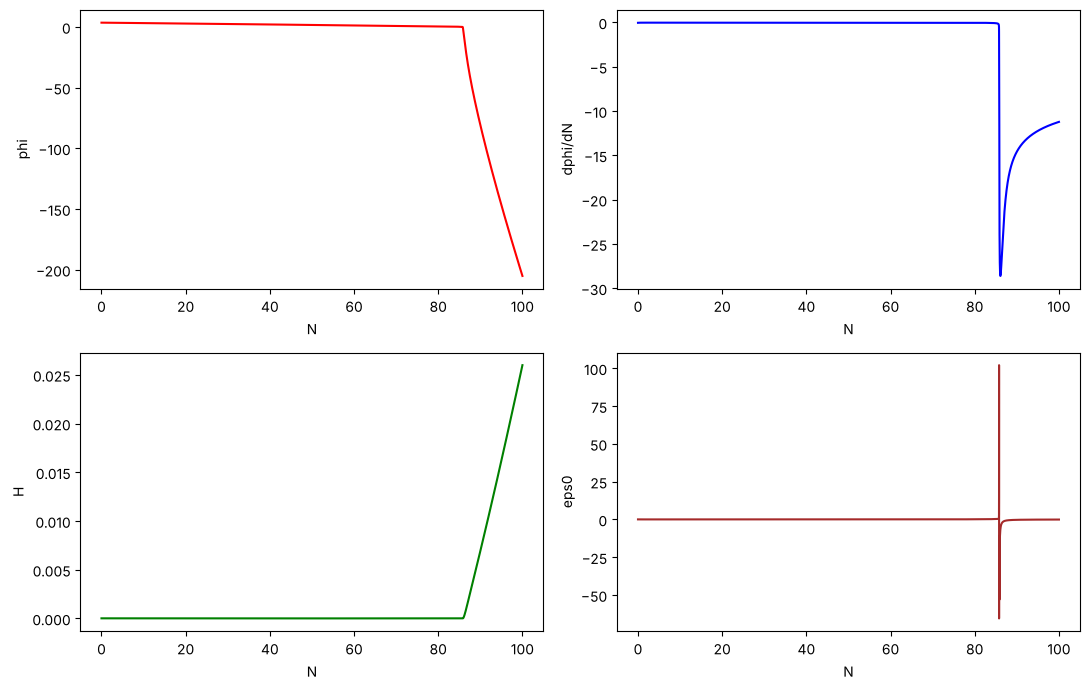

In [6]:
def show(fig, name):
    if SAVE_FIGS:
        fig.savefig(name, dpi=150)
    plt.show()

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, y, lab, col in zip(axs.flat, [phi, dphi, Hsol, eps0],
                           ["phi", "dphi/dN", "H", "eps0"],
                           ["red", "blue", "green", "brown"]):
    ax.plot(efolds, y, col)
    ax.set_xlabel("N"); ax.set_ylabel(lab)
fig.tight_layout()
show(fig, "fig_background.png")

## 6. Конец инфляции, пивот и нормировка масштабного фактора

In [7]:
# момент чуть после конца инфляции (eps > 1.0001) — обрезаем массивы, чтобы избежать численных ошибок
i = 0
while i < len(efolds) and not (eps0[i] > 1.0001 and i > 3000):
    i += 1
i += 1   # как в оригинале: индекс сдвинут на 1 после срабатывания условия
efolds_1 = efolds[:i].copy()
Hsol_1   = Hsol[:i].copy()
print(len(efolds_1), '   ', len(efolds))

# конец инфляции: eps = 1
i = 0
while i < len(efolds_1) and not (eps0[i] > 1 and i > 3000):
    i += 1
iend = i

# выход пивота за горизонт: N_end - N_before_end
iout = int(np.argmax(efolds_1 > efolds_1[iend] - N_before_end))

ai = kpivot/(np.exp(efolds_1[iout])*Hsol[iout])

print(f"N_end   = {efolds_1[iend]:.4f},  phi_end = {phi[iend]:.4f}")
print(f"N_pivot = {efolds_1[iout]:.4f},  phi_piv = {phi[iout]:.4f}")
print(f"a_i     = {ai:.4e}")

857370     1000000


N_end   = 85.7369,  phi_end = 0.0294
N_pivot = 20.7370,  phi_piv = 2.7566
a_i     = 4.8069e-06


## 7. Коэффициенты уравнений для возмущений

$\ddot\zeta + (3H + \dot G_S/G_S)\dot\zeta + c_S^2 k^2/a^2\,\zeta = 0$ и аналогично для h с $G_T, c_T^2 = F_T/G_T$ (переписано в e-фолдах).

In [8]:
def _derivs(dphi, phi, H, V0, alp, C, lamb):
    # dtf = df/dt, dtf2 = d^2f/dt^2
    VB, V_PHIB = potential(phi, V0, alp)
    f, df, df2 = GBfunc(phi, V0, alp, C, lamb)
    Hd, d2phi = Hd_d2phi(phi, dphi, H, V0, alp, C, lamb)
    dtf  = df*dphi*H
    dtf2 = df2*dphi**2*H**2 + df*(d2phi*H**2 + dphi*Hd*H)
    return Hd, d2phi, dtf, dtf2

def coeffs(dphi, phi, H, V0, alp, C, lamb):
    # все коэффициенты для возмущений за один проход (dtf, dtf2 считаются один раз)
    Hd, d2phi, dtf, dtf2 = _derivs(dphi, phi, H, V0, alp, C, lamb)
    X = (1-4*H*dtf)/(H*(1-6*H*dtf))
    G_S = 3 - 12*H*dtf + (-3*H**2 + 0.5*dphi**2*H**2 + 24*H**3*dtf)*X**2
    dG_S = (-12*Hd*H*dtf - 12*H*dtf2
            + (-6*Hd*H**2 + H*dphi*(H**2*d2phi + dphi*Hd*H) + 72*H**3*Hd*dtf + 24*H**3*dtf2)*X**2
            + (-3*H**2 + 0.5*H**2*dphi**2 + 24*H**3*dtf)*2*X
              *(H*(1-6*H*dtf)*(-4*Hd*H*dtf - 4*H*dtf2) - (1-4*H*dtf)*(Hd*H - 12*H**2*Hd*dtf - 6*H**2*dtf2))
              /(H**2*(1-6*H*dtf)**2))
    F_S = ((1-4*H*dtf)**2/(1-6*H*dtf)
           + 2*(1-4*H*dtf)*(-4*Hd*H*dtf - 4*H*dtf2)/(H*(1-6*H*dtf))
           - (1-4*H*dtf)**2*(Hd*H - 12*Hd*H**2*dtf - 6*H**2*dtf2)/(H*(1-6*H*dtf))**2
           - 1 + 4*dtf2)
    # формула c_S^2 из оригинального скрипта
    cS2_code = 1 + 4*dtf*16*H**4*dtf**2*(dtf2/dtf - H + Hd*H*(1-4*H*dtf)/(H**2*dtf)) \
                   /(1-4*H*dtf)**2/(H**2*dphi**2 + 1.5*16*H**4*dtf**2/(1-4*H*dtf))
    G_T  = 1 - 4*dtf*H
    dG_T = -4*dtf2*H - 4*dtf*H*Hd
    F_T  = 1 - 4*dtf2
    if CS2_MODE == "code":
        cS2 = cS2_code
    elif CS2_MODE == "FS/GS":
        cS2 = F_S/G_S
    else:
        raise ValueError(CS2_MODE)
    return dict(Hd=Hd, d2phi=d2phi, G_S=G_S, dG_S=dG_S, F_S=F_S, cS2=cS2, cS2_code=cS2_code,
                G_T=G_T, dG_T=dG_T, F_T=F_T, cT2=F_T/G_T)

def z(a, G_S):  return a*(2*G_S)**0.5
def zH(a, G_T): return a*(G_T)**0.5

### Скорости звука вдоль траектории (проверка)

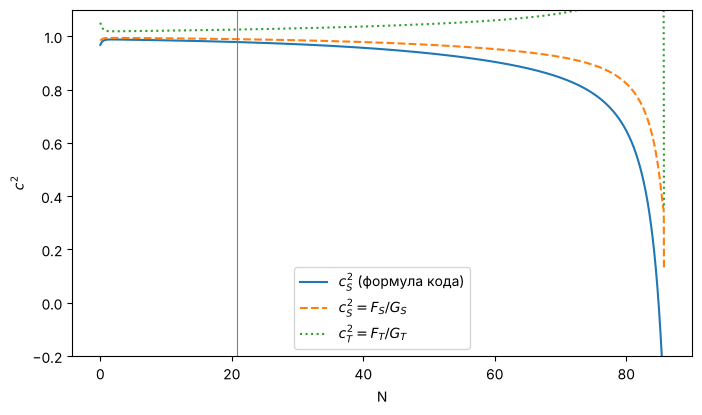

In [9]:
sl = slice(0, iend, 100)
cf = coeffs(dphi[sl], phi[sl], Hsol[sl], V0, alp, C, lamb)
cs2_code, cs2_FSGS, cT2 = cf["cS2_code"], cf["F_S"]/cf["G_S"], cf["cT2"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(efolds[sl], cs2_code, label=r"$c_S^2$ (формула кода)")
ax.plot(efolds[sl], cs2_FSGS, "--", label=r"$c_S^2 = F_S/G_S$")
ax.plot(efolds[sl], cT2, ":", label=r"$c_T^2 = F_T/G_T$")
ax.axvline(efolds_1[iout], color="gray", lw=0.8)
ax.set_xlabel("N"); ax.set_ylabel(r"$c^2$"); ax.legend(); ax.set_ylim(-0.2, 1.1)
show(fig, "fig_sound_speeds.png")

## 8. Система для мод (фон интегрируется заново вместе с возмущениями)

In [10]:
def perturbation(all_var, t, k, ai, V0, alp, C, lamb):
    dphi, phi, H, dksi_re, ksi_re, dksi_im, ksi_im, dh_re, h_re, dh_im, h_im = all_var
    cf = coeffs(dphi, phi, H, V0, alp, C, lamb)
    Hd, d2phi = cf["Hd"], cf["d2phi"]
    G_S, dotG_S, c_S2 = cf["G_S"], cf["dG_S"], cf["cS2"]
    G_T, dotG_T, c2T  = cf["G_T"], cf["dG_T"], cf["cT2"]

    a = ai*exp(t)
    fr_S = -(3 + dotG_S/G_S/H + Hd/H)
    fr_T = -(3 + dotG_T/G_T/H + Hd/H)
    kS = k**2*c_S2/(a**2*H**2)
    kT = k**2*c2T/(a**2*H**2)

    return [d2phi, dphi, Hd,
            fr_S*dksi_re - kS*ksi_re, dksi_re,
            fr_S*dksi_im - kS*ksi_im, dksi_im,
            fr_T*dh_re   - kT*h_re,   dh_re,
            fr_T*dh_im   - kT*h_im,   dh_im]

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx, array[idx]

def boundary(k, t, aH, Nic_cond, Nshs_cond):
    idx_ic,  _ = find_nearest(k - Nic_cond*aH, 0)
    idx_shs, _ = find_nearest(k - Nshs_cond*aH, 0)
    return idx_ic, t[idx_ic], t[idx_shs]

## 9. Цикл по k

Начальные условия Банча–Дэвиса при k = 100·aH (как в оригинале — без учёта c_S, c_T). Для последнего k сохраняется вся эволюция моды для графиков. На одно k уходит ~0.1–0.2 с, весь цикл — несколько минут.

In [11]:
def solve_mode(k, keep_history=False):
    i_in, Nic, Nshs = boundary(k, efolds_1, ai*np.exp(efolds_1)*Hsol_1, 100, 1e-5)
    cf = coeffs(dphi[i_in], phi[i_in], Hsol_1[i_in], V0, alp, C, lamb)
    G_S1, G_T1, dG_S1, dG_T1 = cf["G_S"], cf["G_T"], cf["dG_S"], cf["dG_T"]
    a_in = ai*exp(efolds_1[i_in])

    ksi_re = 1/np.sqrt(2*k)/z(a_in, G_S1)
    h_re   = 1/np.sqrt(2*k)/zH(a_in, G_T1)
    dksi_re = -ksi_re*(dG_S1/(2*Hsol_1[i_in]*G_S1) + 1)
    dh_re   = -h_re*(dG_T1/(2*Hsol_1[i_in]*G_T1) + 1)
    dksi_im = -ksi_re*k/(a_in*Hsol_1[i_in])
    dh_im   = -h_re*k/(a_in*Hsol_1[i_in])

    all_var = [dphi[i_in], phi[i_in], Hsol_1[i_in],
               dksi_re, ksi_re, dksi_im, 0.0, dh_re, h_re, dh_im, 0.0]
    N_pert = np.arange(Nic, Nshs, 0.0001)
    s = odeint(perturbation, all_var, N_pert, args=(k, ai, V0, alp, C, lamb), atol=1e-8)

    ksi_r, ksi_i, h_r, h_i = s[-1, 4], s[-1, 6], s[-1, 8], s[-1, 10]
    Ps = k**3/(2*np.pi**2)*(ksi_r**2 + ksi_i**2)
    Pt = 8*k**3/(2*np.pi**2)*(h_r**2 + h_i**2)
    return (Ps, Pt, (N_pert, s)) if keep_history else (Ps, Pt, None)

P_s = np.zeros(Nk); P_t = np.zeros(Nk)
t0 = time.time()
for i, k in enumerate(k_grid):
    P_s[i], P_t[i], hist = solve_mode(k, keep_history=(i == Nk-1))
    if i % 100 == 0:
        print(f"{i:4d}/{Nk}  k = {k:.4f}  P_s = {P_s[i]:.4e}  r = {P_t[i]/P_s[i]:.5f}   [{time.time()-t0:.0f} с]")
print(f"готово за {time.time()-t0:.0f} с")

   0/1000  k = 0.0100  P_s = 1.2407e-09  r = 0.01777   [0 с]


 100/1000  k = 0.0200  P_s = 1.2028e-09  r = 0.01799   [12 с]


 200/1000  k = 0.0300  P_s = 1.1810e-09  r = 0.01812   [24 с]


 300/1000  k = 0.0400  P_s = 1.1657e-09  r = 0.01821   [35 с]


 400/1000  k = 0.0500  P_s = 1.1538e-09  r = 0.01829   [46 с]


...

 600/1000  k = 0.0700  P_s = 1.1363e-09  r = 0.01840   [66 с]


 700/1000  k = 0.0800  P_s = 1.1293e-09  r = 0.01844   [75 с]


 800/1000  k = 0.0900  P_s = 1.1232e-09  r = 0.01849   [83 с]


 900/1000  k = 0.1000  P_s = 1.1177e-09  r = 0.01852   [93 с]


готово за 101 с


## 10. Результаты: $A_s$, $r$, $n_s$, $n_t$

Наклоны — линейный фит $\log P(\log k)$ по всей сетке (как в оригинале). Амплитуды печатаются на пивоте k = 0.05 (в оригинале `P_s` печаталось при последнем k ≈ 0.11).

In [12]:
r    = P_t/P_s
logk = np.log(k_grid)
A = np.vstack([logk, np.ones_like(logk)]).T
n_s_m1, _ = np.linalg.lstsq(A, np.log(P_s), rcond=None)[0]
n_t,    _ = np.linalg.lstsq(A, np.log(P_t), rcond=None)[0]

print(f"CS2_MODE = {CS2_MODE!r}")
print(f"k_pivot = {k_grid[i_piv_k]:.4f}")
print(f"A_s = P_s(k_pivot) = {P_s[i_piv_k]:.4e}")
print(f"P_t(k_pivot)       = {P_t[i_piv_k]:.4e}")
print(f"r   = {r[i_piv_k]:.5f}")
print(f"n_s = {n_s_m1 + 1:.5f}")
print(f"n_t = {n_t:.5f}")

CS2_MODE = 'code'
k_pivot = 0.0500
A_s = P_s(k_pivot) = 1.1538e-09
P_t(k_pivot)       = 2.1106e-11
r   = 0.01829
n_s = 0.95451
n_t = -0.02753


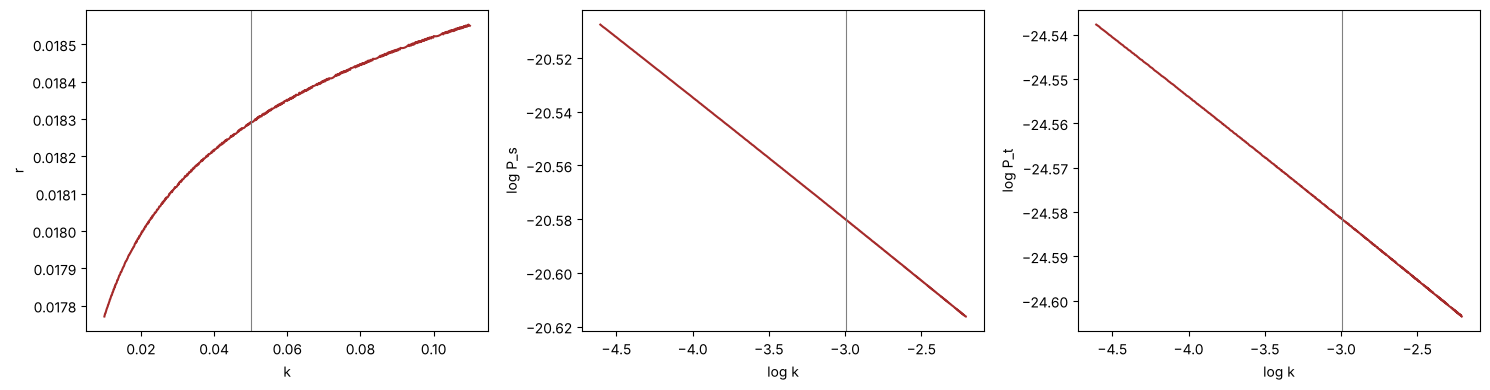

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(k_grid, r, "brown");       axs[0].set_xlabel("k");     axs[0].set_ylabel("r")
axs[1].plot(logk, np.log(P_s), "brown"); axs[1].set_xlabel("log k"); axs[1].set_ylabel("log P_s")
axs[2].plot(logk, np.log(P_t), "brown"); axs[2].set_xlabel("log k"); axs[2].set_ylabel("log P_t")
for ax in axs: ax.axvline(kpivot if ax is axs[0] else np.log(kpivot), color="gray", lw=0.8)
fig.tight_layout()
show(fig, "fig_spectra.png")

### Эволюция мод для последнего k = 0.1099

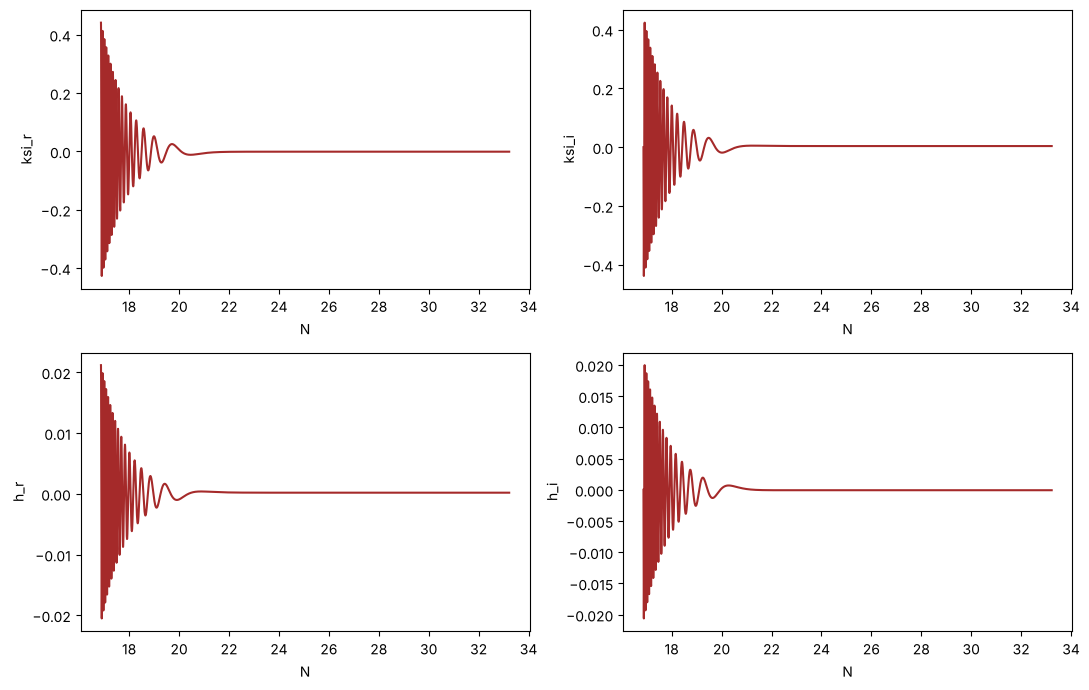

In [14]:
N_pert, s = hist
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, j, lab in zip(axs.flat, [4, 6, 8, 10], ["ksi_r", "ksi_i", "h_r", "h_i"]):
    ax.plot(N_pert, s[:, j], "brown")
    ax.set_xlabel("N"); ax.set_ylabel(lab)
fig.tight_layout()
show(fig, "fig_modes.png")